# BI e Analytics do preço do GLP P13 no Rio Grande do Sul
**Leonardo Bilhalva Silva · PUCRS · Fase 2**

Dados da ANP: GLP P13 em 35 municípios, de 06/07 a 27/12/2025.


## Preparação


In [1]:
import importlib.util
import subprocess
import sys
packages = {"pandas": "pandas>=2.2,<3.1", "numpy": "numpy>=1.26,<3",
            "sklearn": "scikit-learn>=1.5,<1.10", "plotly": "plotly>=5.24,<7",
            "matplotlib": "matplotlib>=3.8,<4", "ipywidgets": "ipywidgets>=8.1,<9",
            "openpyxl": "openpyxl>=3.1,<4"}
missing = [requirement for module, requirement in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Dependências disponíveis.")

Dependências disponíveis.


In [2]:
from pathlib import Path
import base64
import io
import zipfile

ROOT = Path.cwd() / "glp_bi"
ROOT.mkdir(exist_ok=True)
PACOTE = "..."
with zipfile.ZipFile(io.BytesIO(base64.b64decode(PACOTE))) as archive:
    for name in archive.namelist():
        target = (ROOT / name).resolve()
        if not target.is_relative_to(ROOT.resolve()):
            raise ValueError("Caminho de arquivo inválido no pacote.")
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.read(name))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Projeto restaurado em", ROOT)

Projeto restaurado em /workspace/scratch/5f79921f5db1/fase2/qa/notebook/glp_bi


## Coleta e processamento


In [3]:
import json
import pandas as pd
from IPython.display import display, Image, HTML
from src.pipeline import executar_pipeline
from src.analytics import executar_analytics
from src.dashboards import exportar_dashboards, mercado, qualidade, previsao

from coletar_fontes import atualizar
atualizar(ROOT)
clean, weekly, audit = executar_pipeline(ROOT)
analytics = executar_analytics(weekly, ROOT)
exportar_dashboards(weekly, ROOT)
print(f"{audit['coletas_validas']} coletas válidas · {audit['pares_conciliados']}/{audit['pares_observados']} pares conciliados")
display(pd.Series(audit["status"], name="Pares de município e semana").to_frame())
print("H1", audit["h1_atendida"], "· H2", audit["h2_atendida"])

3471 coletas válidas · 367/367 pares conciliados
H1 True · H2 True


,Pares de município e semana
Sem dados,508
Elegível,343
Amostra reduzida,24


## Mercado
Em Pelotas, a média passou de R$ 111,39 para R$ 115,13, alta de 3,36%. Na última semana, 27 municípios atenderam aos critérios de comparação.

Valores em reais por botijão de 13 kg. A faixa sombreada representa os preços mínimo e máximo coletados.


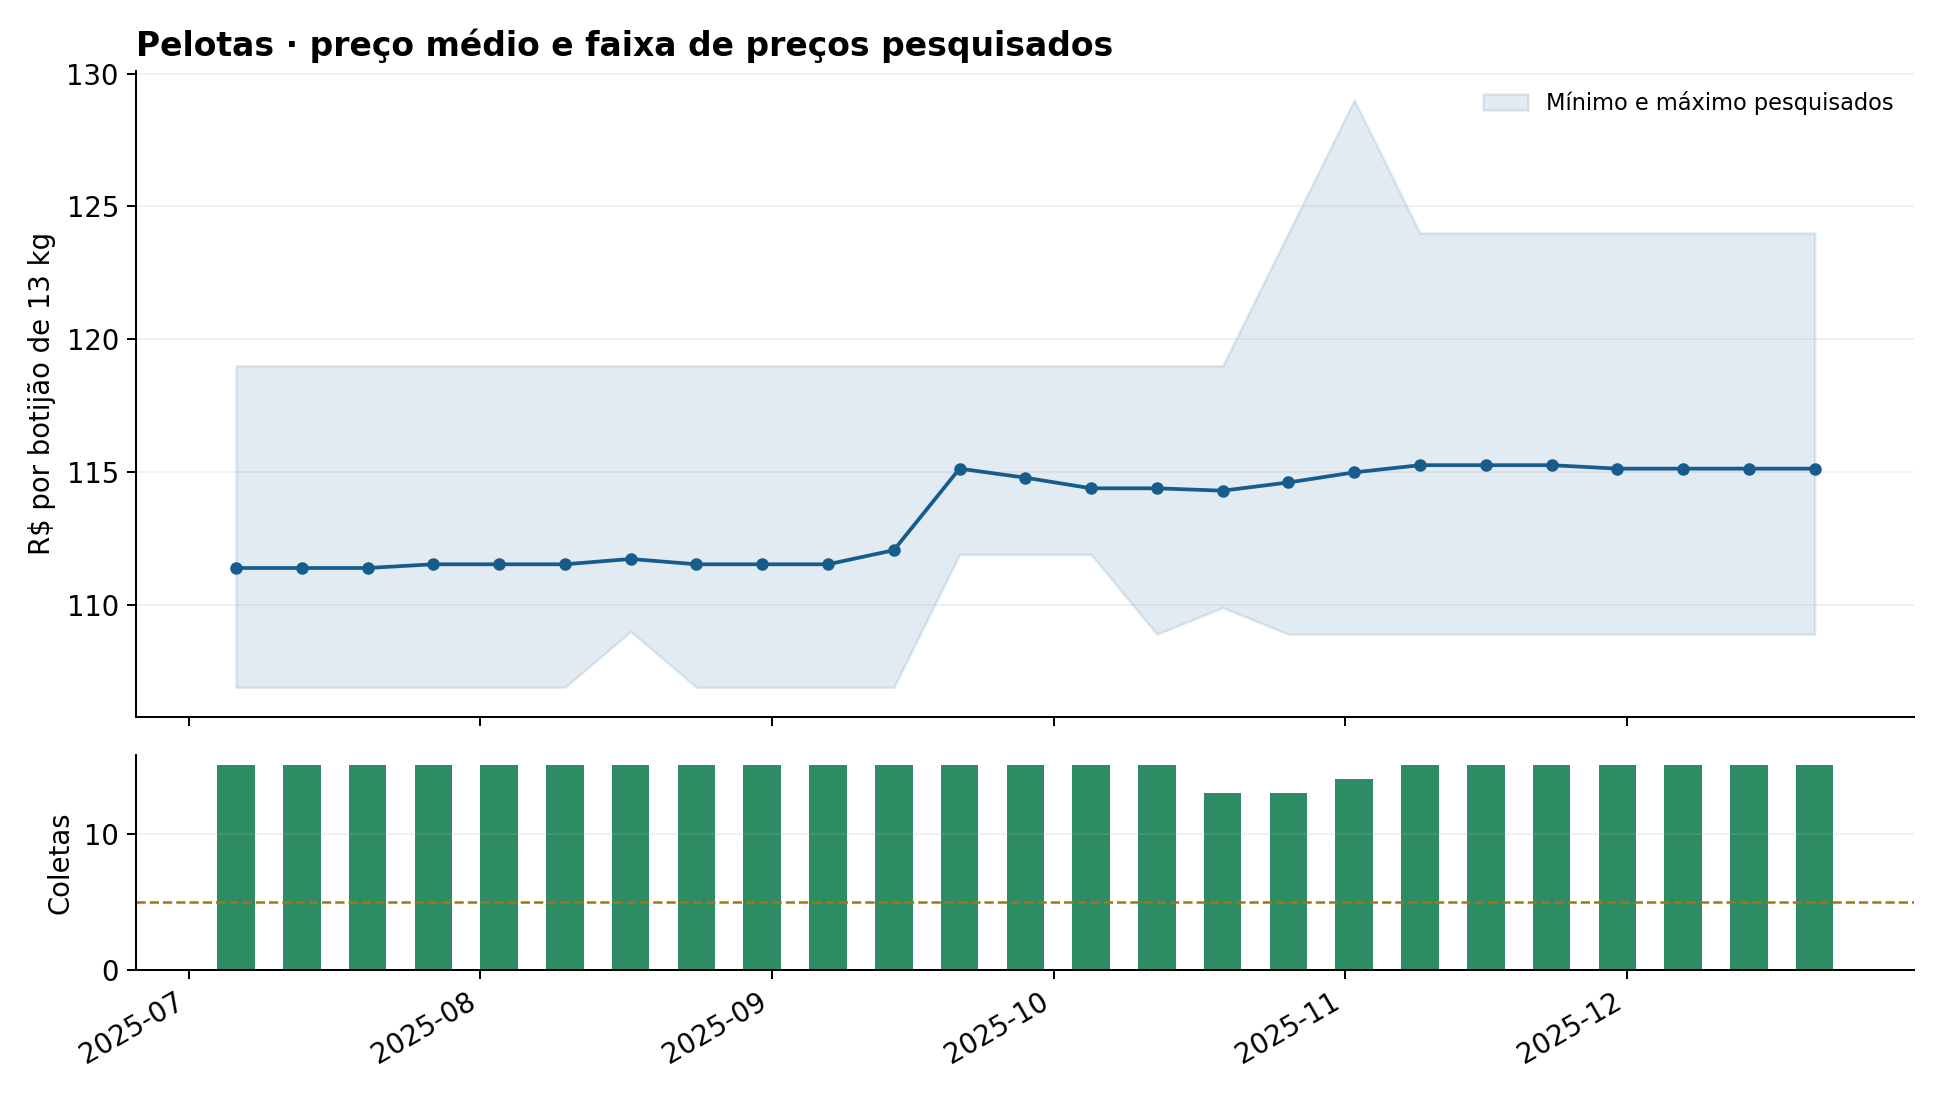

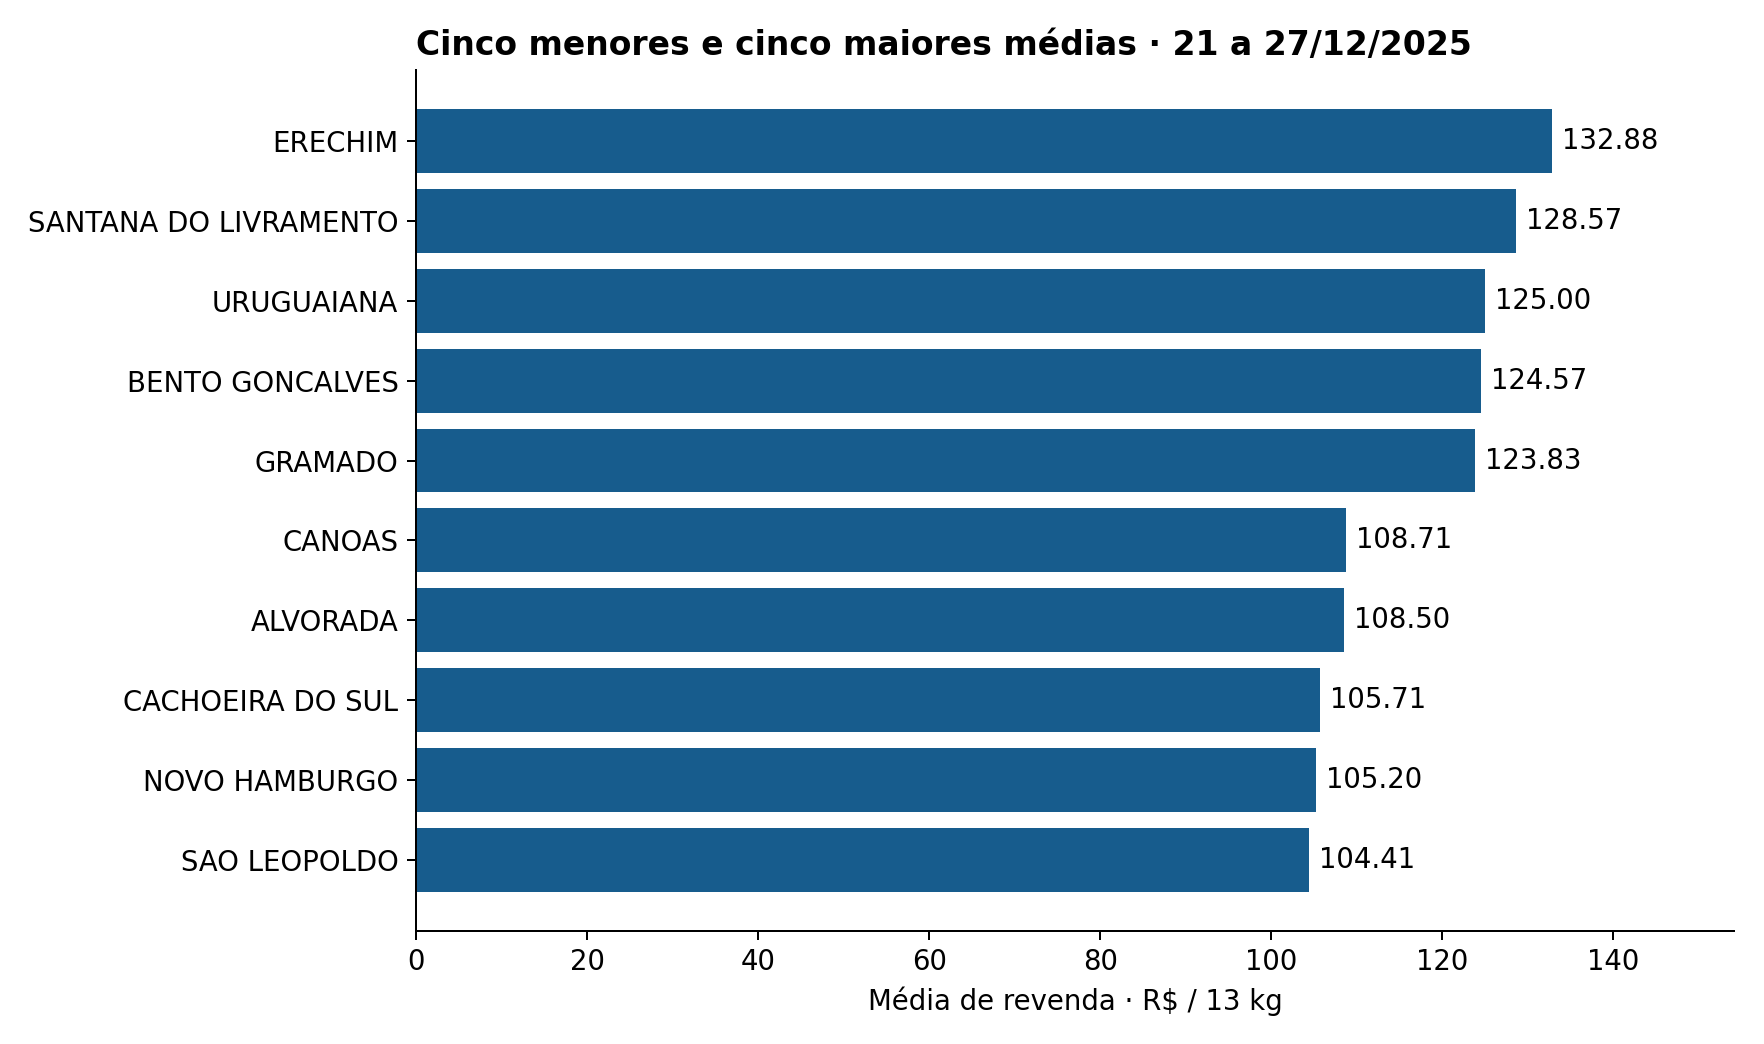

,municipio,preco_medio,n_coletas,amplitude,variacao_pct
0,SAO LEOPOLDO,104.41,7,5.90,-0.143458
1,NOVO HAMBURGO,105.20,10,15.01,0.727691
2,CACHOEIRA DO SUL,105.71,7,10.00,-0.676501
3,ALVORADA,108.50,6,3.00,-0.303225
4,CANOAS,108.71,14,10.00,0.610828
5,IJUI,108.85,7,34.00,0.000000
6,SAPUCAIA DO SUL,109.00,7,15.00,1.329367
7,GRAVATAI,109.22,9,17.01,1.656739
8,VIAMAO,109.43,9,17.00,-0.635612
9,ESTEIO,112.14,7,15.00,0.000000


In [4]:
display(Image(filename=str(ROOT / "outputs/mercado.png")))
display(Image(filename=str(ROOT / "outputs/comparacao.png")))
latest = weekly[(weekly["semana"] == weekly["semana"].max()) & weekly["status"].eq("Elegível")]
display(latest[["municipio", "preco_medio", "n_coletas", "amplitude", "variacao_pct"]]
        .sort_values("preco_medio").reset_index(drop=True))

## Qualidade e cobertura
As 367 combinações observadas de município e semana conferiram com a referência da ANP, com tolerância de R$ 0,01 nas médias e contagens iguais.

Das 875 combinações possíveis, 343 são elegíveis, 24 têm amostra reduzida e 508 estão sem dados. A comparação exige pelo menos cinco coletas e conciliação aprovada.


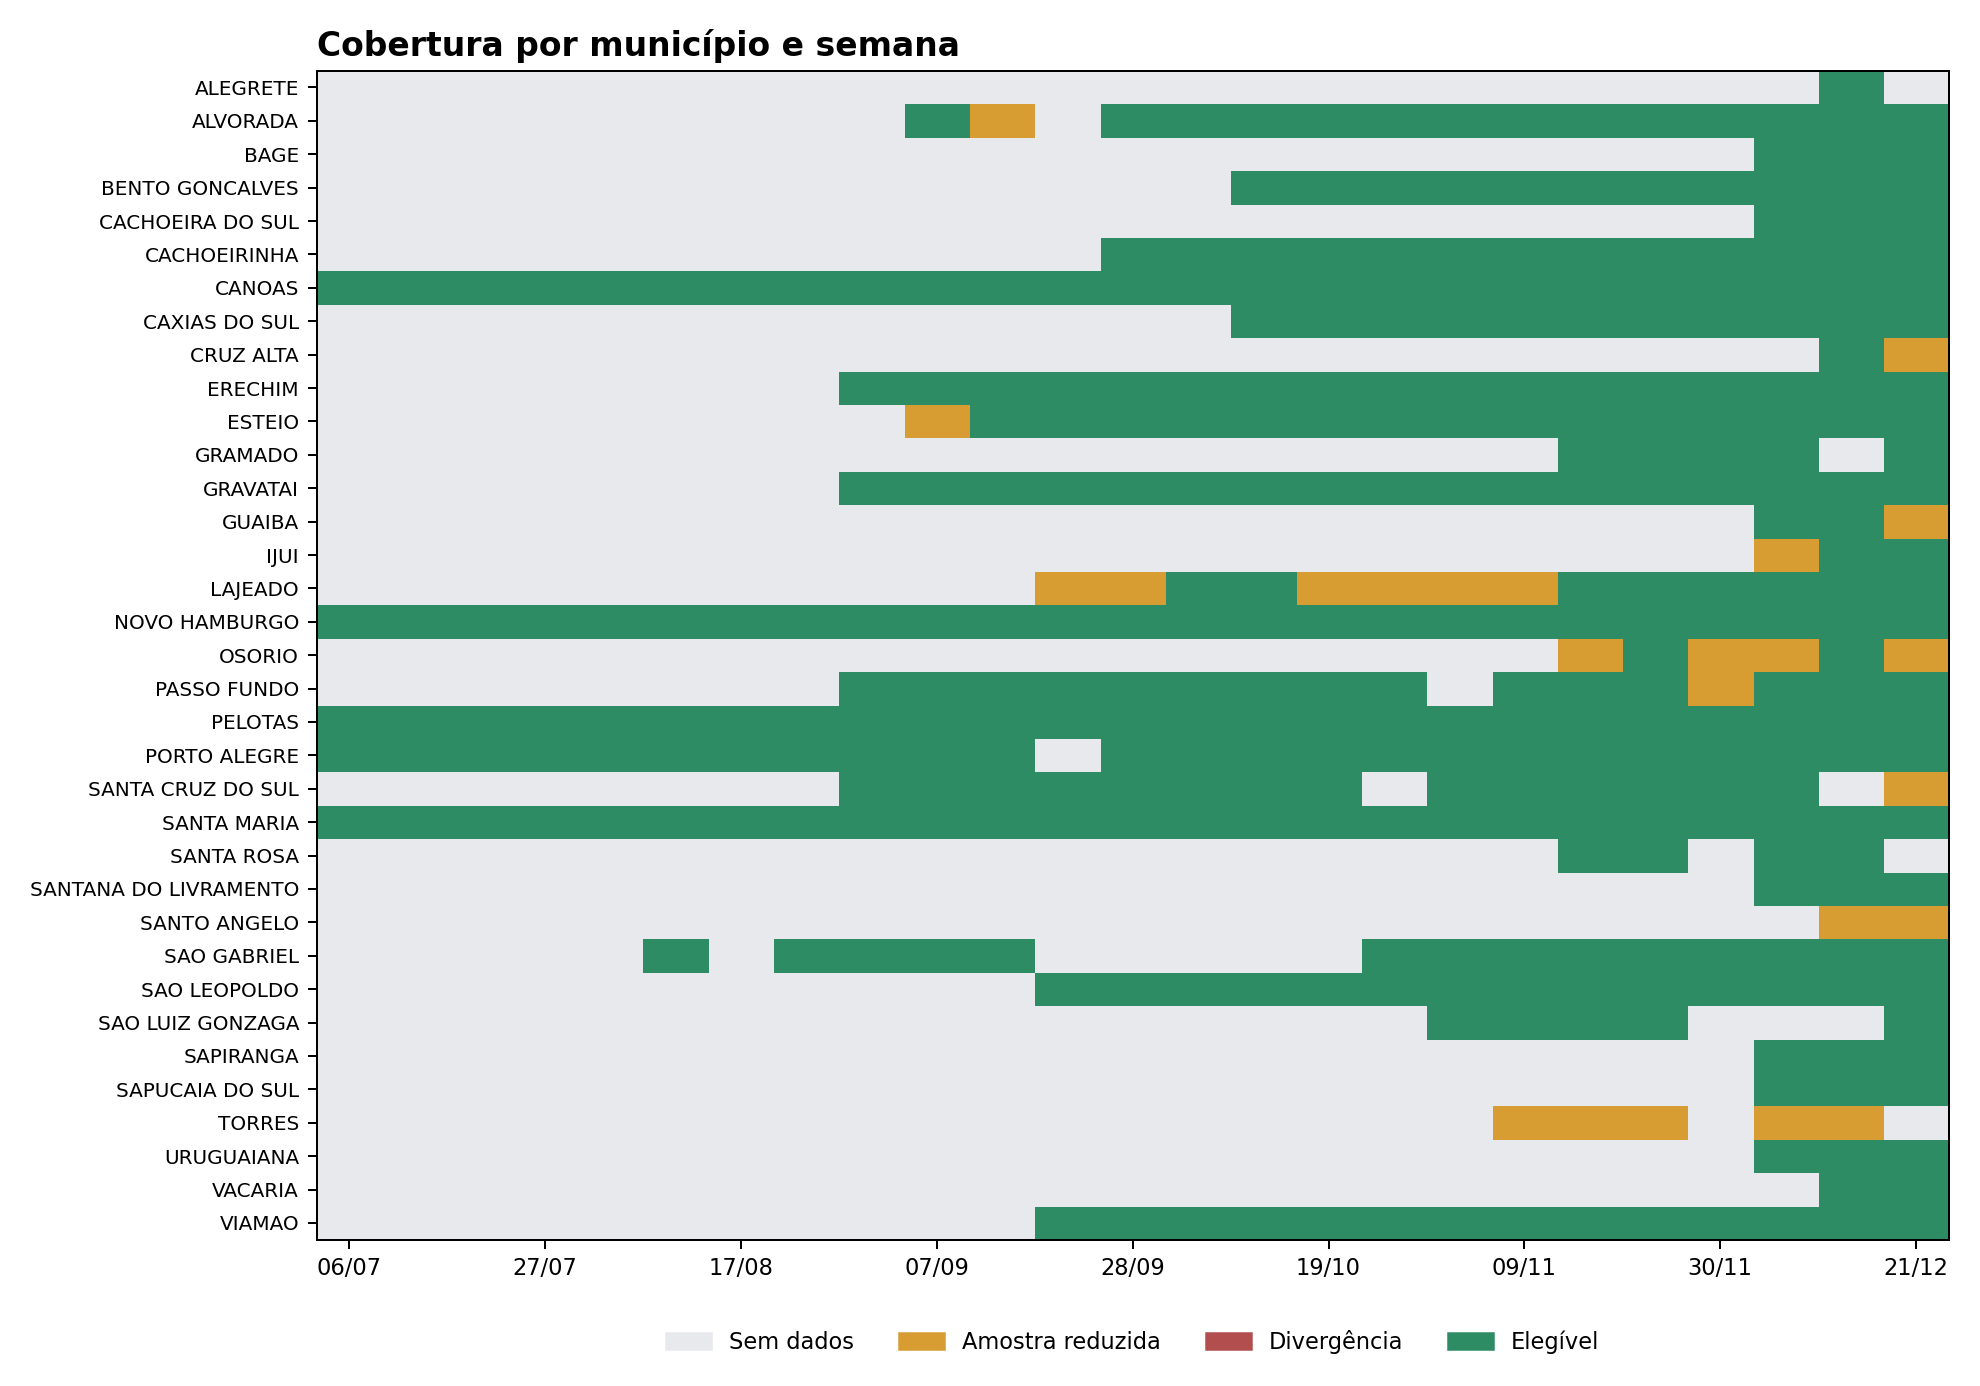

,coletas,conciliado,obtido,esperado,passou
0,0,False,Sem dados,Sem dados,True
1,4,True,Amostra reduzida,Amostra reduzida,True
2,5,True,Elegível,Elegível,True
3,5,False,Divergência,Divergência,True


,name
0,dim_municipio
1,dim_revenda
2,dim_data
3,fato_preco
4,indicador_semanal
5,rejeicoes


In [5]:
display(Image(filename=str(ROOT / "outputs/qualidade.png")))
display(pd.DataFrame(audit["testes_h2"]))
with __import__("sqlite3").connect(ROOT / "data/processed/glp.sqlite") as db:
    display(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", db))

## Previsão
O último preço apresentou o menor MAE de validação (R$ 0,539) e gerou a projeção de R$ 115,13 para as quatro semanas seguintes.

Previsão retrospectiva, com dados até 27/12/2025. O teste cobre apenas cinco semanas estáveis; a faixa projetada é indicativa de erro.


Previsões retrospectivas a partir de dezembro de 2025. Teste de um passo com atualização semanal. Projeção final recursiva de quatro passos. Faixa ilustrativa baseada no percentil 90 do erro de validação e raiz do horizonte, sem garantia de cobertura.


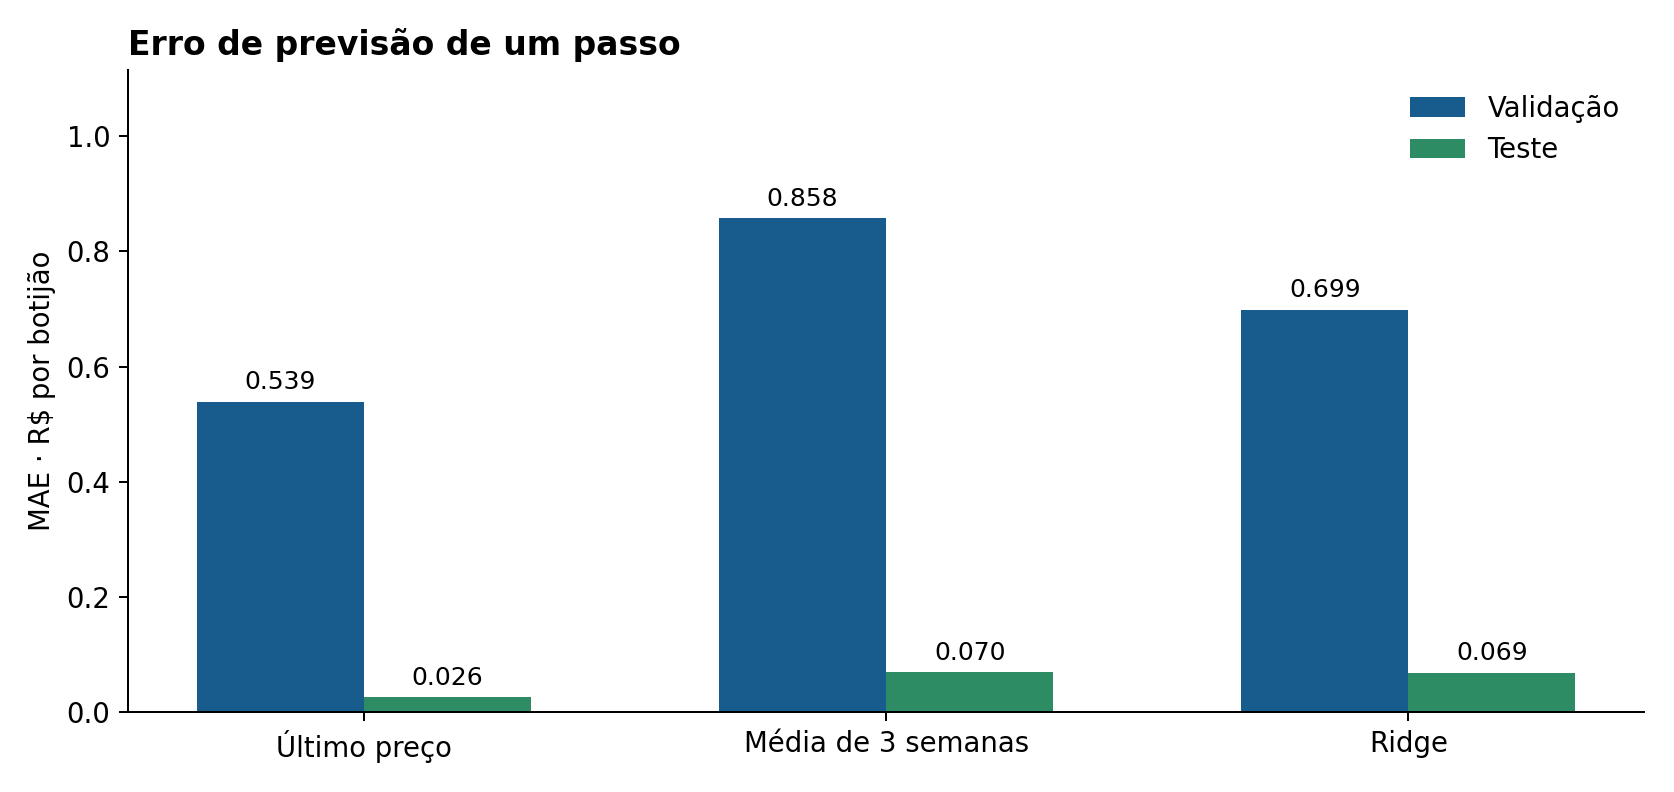

,fase,modelo,n,mae,rmse
0,Validação,Último preço,10,0.539000,1.015032
1,Validação,Média de 3 semanas,10,0.857667,1.294520
2,Validação,Ridge,10,0.698541,1.250290
3,Teste,Último preço,5,0.026000,0.058138
4,Teste,Média de 3 semanas,5,0.070000,0.082932
5,Teste,Ridge,5,0.068890,0.092164


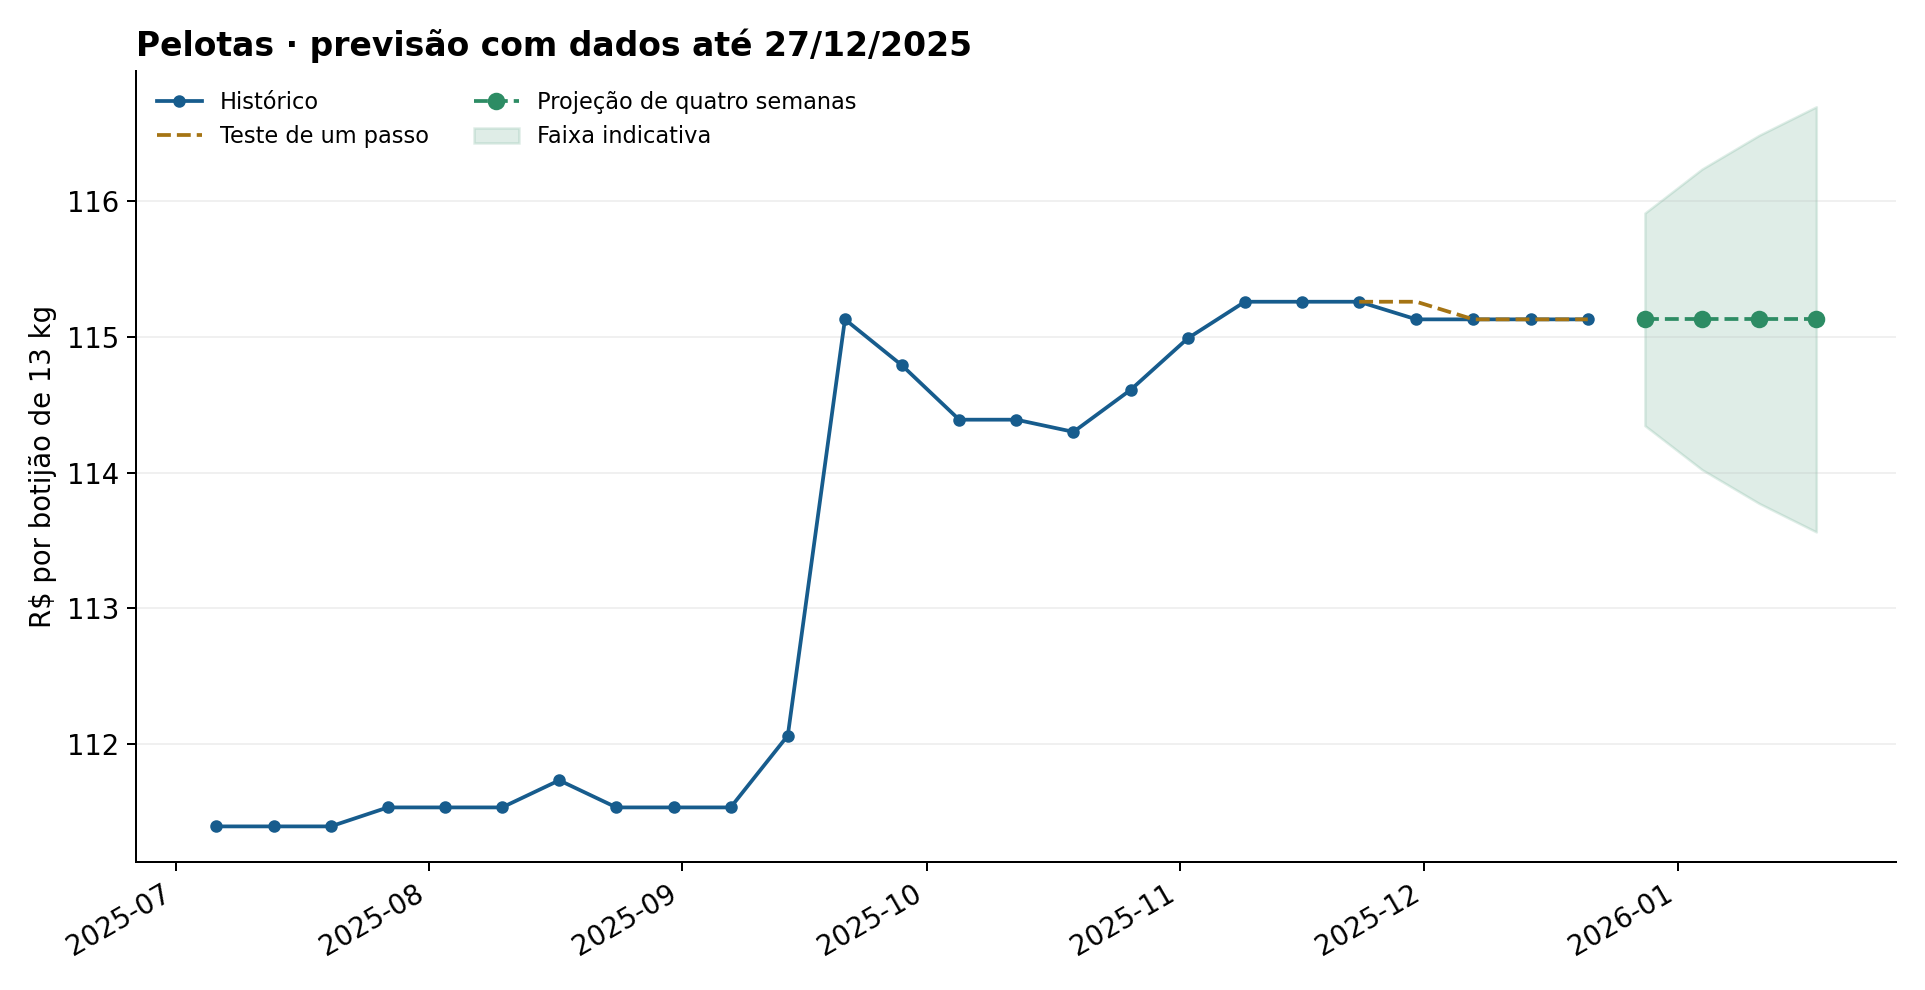

,semana,fim_semana,previsto,ridge_previsto,faixa_inferior,faixa_superior,modelo
0,2025-12-28,2026-01-03,115.13,115.156083,114.346000,115.914000,Último preço
1,2026-01-04,2026-01-10,115.13,115.178686,114.021257,116.238743,Último preço
2,2026-01-11,2026-01-17,115.13,115.195763,113.772072,116.487928,Último preço
3,2026-01-18,2026-01-24,115.13,115.211581,113.562000,116.698000,Último preço


In [6]:
display(Image(filename=str(ROOT / "outputs/modelos.png")))
display(pd.read_csv(ROOT / "outputs/metricas_modelos.csv"))
display(Image(filename=str(ROOT / "outputs/previsao.png")))
display(pd.read_csv(ROOT / "outputs/previsoes.csv"))
print(analytics["nota"])

## Consulta interativa


In [7]:
try:
    import google.colab
    from google.colab import output
    output.enable_custom_widget_manager()
    import ipywidgets as widgets
    from IPython.display import clear_output
    city = widgets.Dropdown(options=sorted(weekly["municipio"].unique()), value="PELOTAS", description="Município")
    week = widgets.Dropdown(options=[(d.strftime("%d/%m/%Y"), d) for d in sorted(weekly["semana"].unique())],
                            value=weekly["semana"].max(), description="Semana")
    city_out, week_out = widgets.Output(), widgets.Output()
    def atualizar_cidade(change=None):
        with city_out:
            clear_output(wait=True)
            mercado(weekly, city.value).show(renderer="colab")
    def atualizar_semana(change=None):
        with week_out:
            clear_output(wait=True)
            selected = weekly[weekly["semana"].eq(week.value) & weekly["status"].eq("Elegível")]
            display(selected[["municipio","preco_medio","n_coletas","variacao_pct"]].sort_values("preco_medio"))
    city.observe(atualizar_cidade, names="value")
    week.observe(atualizar_semana, names="value")
    display(city, city_out, week, week_out)
    atualizar_cidade()
    atualizar_semana()
    qualidade(weekly).show(renderer="colab")
    previsao(weekly, ROOT).show(renderer="colab")
except ImportError:
    print("Os filtros são ativados no Google Colab. Os gráficos salvos e as tabelas acima já contêm os resultados.")

Os filtros são ativados no Google Colab. Os gráficos salvos e as tabelas acima já contêm os resultados.


## Testes e exportação


In [8]:
subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", str(ROOT), "-p", "tests_*.py"],
               cwd=ROOT, check=True)
import shutil
exported = shutil.make_archive(str(ROOT.parent / "GLP_BI_Resultados"), "zip", ROOT)
print("Pacote completo gerado em", exported)
try:
    from google.colab import files
    files.download(exported)
except ImportError:
    pass

Pacote completo gerado em /workspace/scratch/5f79921f5db1/fase2/qa/notebook/GLP_BI_Resultados.zip
